In [1]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

c:\Users\princ\ALL PROGRAMS\DATA-SCIENCE\LANGRAPH\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

True

In [3]:
class ParentState(TypedDict):

    question: str
    answer_eng: str
    answer_hin: str
    

In [4]:
parent_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash')
subgraph_llm = ChatGoogleGenerativeAI(model='gemini-2.5-flash-lite')

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.
Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [5]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [6]:
subgraph_builder = StateGraph(ParentState)

subgraph_builder.add_node('translate_text', translate_text)

subgraph_builder.add_edge(START, 'translate_text')
subgraph_builder.add_edge('translate_text', END)

subgraph = subgraph_builder.compile()

In [7]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [8]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

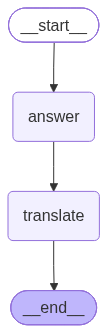

In [9]:
graph = parent_builder.compile()

graph

In [10]:
result = graph.invoke({'question': 'What is quantum physics'})

In [11]:
print(result)

{'question': 'What is quantum physics', 'answer_eng': 'Quantum physics, also known as quantum mechanics, is a fundamental branch of physics that describes the behavior of matter and energy at the atomic and subatomic levels.\n\nHere\'s a breakdown of what that means:\n\n1.  **The "Very Small":** Classical physics (like Newton\'s laws) works great for everyday objects (planets, cars, apples). But when you shrink down to the size of atoms, electrons, photons, and other tiny particles, the classical rules break down. Quantum physics provides a new set of rules to understand how these microscopic entities behave.\n\n2.  **"Quantized" Nature:** The word "quantum" comes from the Latin word "quantus," meaning "how much." A key idea in quantum physics is that certain physical properties, like energy, momentum, and angular momentum, don\'t exist in continuous values but rather in discrete, minimum amounts called "quanta." Think of it like a staircase instead of a ramp – you can only be on speci